# Housing Problem – implementation

Compact MILP for the Dutch housing problem, solved for 23, 40 and 56 floors.
Requires `pulp` and `openpyxl`; put `Housing_Problem_-_parameter_values.xlsx` in the same folder.

In [1]:
# !pip install pulp openpyxl
from collections import Counter, defaultdict
import openpyxl
import pulp
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle

### What runs on *Run All*
The main model (sections 1–8) always runs and takes a few seconds.
The optional parts are switched on or off here.

In [2]:
RUN_SENSITIVITY = True    # section 9  (~30 s): report section 5 and Figure 2
RUN_CROSSCHECK  = False   # section 12 (slow!): independent floor-by-floor model, up to
                          #   CROSSCHECK_TIME_LIMIT seconds per case; only for validation

CROSSCHECK_CASES      = [23]       # floors to cross-check
CROSSCHECK_SOLVER     = "cbc"      # "cbc" or "highs" (needs: pip install highspy)
CROSSCHECK_TIME_LIMIT = 1800       # seconds per case

## 1. Parameters

In [3]:
DATA_FILE = "Housing_Problem_-_parameter_values.xlsx"
FLOOR_HEIGHT = 3                      # m per floor: 69 m = 23, 120 m = 40, 168 m = 56 floors

OWNERS  = ["corporation", "investor", "private"]
SECTORS = ["social", "middle", "free"]
MODES   = {"SM": ["social", "middle"],   # floor modes (R11)
           "MF": ["middle", "free"]}

ALPHA = {"social": 0.40, "middle": 0.40}   # R1, R2  minimum sector share
A_MIN = {"social": 40,   "middle": 50}     # R3, R4  minimum average area
BETA  = 0.70                                # R9      minimum investor share

# R5-R8: minimum area per (sector, owner); None = not allowed
MIN_AREA = {
    ("social", "corporation"): 40,   ("middle", "corporation"): 50,   ("free", "corporation"): None,
    ("social", "investor"): 0,       ("middle", "investor"): 0,       ("free", "investor"): 60,
    ("social", "private"): 0,        ("middle", "private"): 0,        ("free", "private"): 60,
}

## 2. Data

In [4]:
wb = openpyxl.load_workbook(DATA_FILE, data_only=True)

# n[d][s]: number of apartments of area s on a floor of design d
n = defaultdict(dict)
for area, design, count in list(wb["number_of_apartments"].iter_rows(values_only=True))[1:]:
    if area is not None and count:
        n[design][int(area)] = int(count)
DESIGNS = sorted(n)
AREAS = sorted({s for d in DESIGNS for s in n[d]})
n_tot = {d: sum(n[d].values()) for d in DESIGNS}

# profit[N][(s, k, o)] for every tower height
profit = {}
for ws in wb.worksheets:
    if ws.title.startswith("profit_height_"):
        N = int(ws.title.rsplit("_", 1)[1]) // FLOOR_HEIGHT
        profit[N] = {(int(s), k, o): float(p)
                     for k, s, o, p in list(ws.iter_rows(values_only=True))[1:] if k is not None}
profit = dict(sorted(profit.items()))

print("Designs:", DESIGNS)
print("Areas:  ", AREAS)
print("Cases:  ", list(profit))

Designs: ['aa', 'ab', 'ac', 'bb', 'bc', 'cc', 'cd', 'ce', 'dd', 'de', 'ee']
Areas:   [36, 42, 48, 52, 60, 68, 70, 71, 96, 131]
Cases:   [23, 40, 56]


## 3. Derived index sets
- $\mathcal{G}$: floor groups (owner, mode); (corporation, MF) is dropped (R8)
- $\Omega$: admissible (area, owner, mode, sector) combinations (R5–R8)

In [5]:
def allowed(s, k, o):
    m = MIN_AREA[(k, o)]
    return m is not None and s >= m

G = [(o, t) for o in OWNERS for t in MODES
     if not (t == "MF" and MIN_AREA[("free", o)] is None)]
OMEGA = [(s, o, t, k) for (o, t) in G for k in MODES[t] for s in AREAS if allowed(s, k, o)]
print(f"|G| = {len(G)}, |Omega| = {len(OMEGA)}")

|G| = 5, |Omega| = 88


## 4. Model

In [6]:
def build_model(N):
    p = profit[N]
    m = pulp.LpProblem(f"Housing_{N}", pulp.LpMaximize)

    # decision variables
    y = {(d, o, t): pulp.LpVariable(f"y_{d}_{o}_{t}", lowBound=0, cat="Integer")
         for d in DESIGNS for (o, t) in G}
    # variable name = (area, owner, floor group (owner, mode), sector); keep it: CBC's choice among
    # equally profitable designs depends on variable names, and this one reproduces the report's floor plans
    x = {(s, o, t, k): pulp.LpVariable(f"x_{s}_{o}_{o}_{t}_{k}", lowBound=0, cat="Integer")
         for (s, o, t, k) in OMEGA}

    U = pulp.lpSum(n_tot[d] * y[d, o, t] for (d, o, t) in y)                       # all apartments
    X = {k: pulp.lpSum(v for (s, o, t, kk), v in x.items() if kk == k) for k in SECTORS}
    Q = {k: pulp.lpSum(s * v for (s, o, t, kk), v in x.items() if kk == k) for k in SECTORS}

    # (1) objective
    m += pulp.lpSum(p[s, k, o] * v for (s, o, t, k), v in x.items())
    # (2) number of floors
    m += pulp.lpSum(y.values()) == N
    # (3) linking: every built apartment gets exactly one admissible sector
    for (o, t) in G:
        for s in AREAS:
            m += (pulp.lpSum(x[s, o, t, k] for k in MODES[t] if (s, o, t, k) in x)
                  == pulp.lpSum(n[d].get(s, 0) * y[d, o, t] for d in DESIGNS))
    # (4) R1, R2
    for k in ALPHA:
        m += X[k] >= ALPHA[k] * U
    # (5) R3, R4
    for k in A_MIN:
        m += Q[k] >= A_MIN[k] * X[k]
    # (6) R9: apartments on investor floors
    m += pulp.lpSum(v for (s, o, t, k), v in x.items() if o == "investor") >= BETA * U
    # R5-R8: index set OMEGA | R10, R11: indices o, t of y | R12: sorting afterwards
    return m, y, x

## 5. From counts to an explicit tower (R12: sort by smallest apartment)

In [7]:
def build_tower(y, x):
    floors = []
    for (d, o, t), v in y.items():
        for _ in range(round(v.value())):
            apts = sorted(s for s, c in n[d].items() for _ in range(c))
            floors.append({"design": d, "owner": o, "mode": t, "apts": [[s, None] for s in apts]})
    for (o, t) in G:
        group = [f for f in floors if (f["owner"], f["mode"]) == (o, t)]
        for s in AREAS:
            slots = [a for f in group for a in f["apts"] if a[0] == s]
            labels = [k for k in MODES[t] if (s, o, t, k) in x
                      for _ in range(round(x[s, o, t, k].value()))]
            assert len(labels) == len(slots)
            for a, k in zip(slots, labels):
                a[1] = k
    floors.sort(key=lambda f: (min(a[0] for a in f["apts"]), f["owner"], f["design"]))   # R12
    return floors

## 6. Verify all 12 restrictions on the explicit tower

In [8]:
def verify(floors, N, objective):
    apts = [(a[0], a[1], f["owner"]) for f in floors for a in f["apts"]]
    tot = len(apts)
    soc = [a for a in apts if a[1] == "social"]
    mid = [a for a in apts if a[1] == "middle"]
    mins = [min(a[0] for a in f["apts"]) for f in floors]
    checks = {
        "N floors": len(floors) == N,
        "R1":  len(soc) >= 0.40 * tot,
        "R2":  len(mid) >= 0.40 * tot,
        "R3":  sum(a[0] for a in soc) >= 40 * len(soc),
        "R4":  sum(a[0] for a in mid) >= 50 * len(mid),
        "R5":  all(a[0] >= 40 for a in soc if a[2] == "corporation"),
        "R6":  all(a[0] >= 50 for a in mid if a[2] == "corporation"),
        "R7":  all(a[0] >= 60 for a in apts if a[1] == "free"),
        "R8":  not any(a[1] == "free" and a[2] == "corporation" for a in apts),
        "R9":  sum(a[2] == "investor" for a in apts) >= 0.70 * tot,
        "R10": True,   # owner is stored per floor
        "R11": all(not ({"social", "free"} <= {a[1] for a in f["apts"]}) for f in floors),
        "R12": all(mins[i] <= mins[i + 1] for i in range(len(mins) - 1)),
        "profit": abs(sum(profit[N][s, k, o] for s, k, o in apts) - objective) < 1e-4,
    }
    return checks

## 7. Solve the three cases

In [9]:
towers, objective = {}, {}
for N in profit:
    m, y, x = build_model(N)
    m.solve(pulp.PULP_CBC_CMD(msg=False))
    obj = pulp.value(m.objective)
    floors = build_tower(y, x)
    towers[N], objective[N] = floors, obj
    checks = verify(floors, N, obj)

    apts = [(a[0], a[1], f["owner"]) for f in floors for a in f["apts"]]
    sec = Counter(a[1] for a in apts)
    own = Counter(a[2] for a in apts)
    print(f"=== {N} floors: {pulp.LpStatus[m.status]} | {len(m.variables())} variables, "
          f"{len(m.constraints)} constraints")
    print(f"Profit: EUR {obj:,.0f}")
    print(f"Apartments: {len(apts)} | social {sec['social']}, middle {sec['middle']}, free {sec['free']}")
    print(f"Owners: corporation {own['corporation']}, investor {own['investor']}, private {own['private']}")
    print(f"Designs used: {dict(Counter(f['design'] for f in floors))}")
    print("All restrictions satisfied:", all(checks.values()), "\n")

=== 23 floors: Optimal | 143 variables, 56 constraints
Profit: EUR 17,483,911
Apartments: 193 | social 78, middle 78, free 37
Owners: corporation 7, investor 150, private 36
Designs used: {'aa': 11, 'ac': 1, 'cd': 1, 'cc': 1, 'ee': 9}
All restrictions satisfied: True 



=== 40 floors: Optimal | 143 variables, 56 constraints
Profit: EUR 29,622,230
Apartments: 334 | social 134, middle 134, free 66
Owners: corporation 8, investor 262, private 64
Designs used: {'aa': 16, 'ab': 1, 'ac': 5, 'bc': 1, 'cc': 1, 'ee': 16}
All restrictions satisfied: True 



=== 56 floors: Optimal | 143 variables, 56 constraints
Profit: EUR 39,187,429
Apartments: 464 | social 186, middle 186, free 92
Owners: corporation 14, investor 358, private 92
Designs used: {'aa': 24, 'ac': 7, 'cc': 1, 'ce': 1, 'ee': 23}
All restrictions satisfied: True 



## 8. Floor plans (floor 1 = ground floor)

In [10]:
ABBR = {"social": "S", "middle": "M", "free": "F"}
for N, floors in towers.items():
    print(f"=== {N} floors")
    for i, f in enumerate(floors, 1):
        apts = " ".join(f"{s}{ABBR[k]}" for s, k in f["apts"])
        print(f"{i:>3}  {f['design']}  {f['owner']:<12} {apts}")
    print()

=== 23 floors
  1  aa  investor     36S 36S 36S 36S 42S 42S 42S 42S 48M 48M 48M 48M
  2  aa  investor     36S 36S 36S 36S 42S 42S 42S 42S 48M 48M 48M 48M
  3  aa  investor     36S 36S 36S 36S 42S 42S 42S 42S 48M 48M 48M 48M
  4  aa  investor     36S 36S 36S 36S 42S 42S 42S 42S 48M 48M 48M 48M
  5  aa  investor     36S 36S 36S 36S 42S 42S 42S 42S 48M 48M 48M 48M
  6  aa  investor     36S 36S 36S 36S 42S 42S 42S 42S 48M 48M 48M 48M
  7  aa  investor     36S 36S 36S 36S 42S 42S 42S 42M 48M 48M 48M 48M
  8  aa  investor     36S 36S 36S 36S 42M 42M 42M 42M 48M 48M 48M 48M
  9  aa  investor     36S 36S 36S 36S 42M 42M 42M 42M 48M 48M 48M 48M
 10  aa  investor     36S 36S 36S 36S 42M 42M 42M 42M 48M 48M 48M 48M
 11  aa  investor     36S 36S 36S 36S 42M 42M 42M 42M 48M 48M 48M 48M
 12  ac  investor     36S 36S 42M 42M 48M 48M 60M 60M 71M 71M
 13  cd  corporation  60S 60S 70S 71S 71S 96M 96M
 14  cc  investor     60M 60M 60M 60M 71M 71M 71M 71F
 15  ee  private      131F 131F 131F 131F
 16  ee 

## 9. Sensitivity analysis: what does each restriction cost?
Drop one restriction at a time, re-optimise, and compare with the profit of the full model.
The difference is the cost of that restriction to the developer. (R12 never costs anything: Proposition 2.)

In [11]:
def solve_relaxed(N, rule):
    """Same model as build_model, with one restriction (R1-R11) removed. Returns the optimal profit."""
    p = profit[N]
    alpha = {k: a for k, a in ALPHA.items() if not (rule == "R1" and k == "social" or rule == "R2" and k == "middle")}
    a_min = {k: a for k, a in A_MIN.items() if not (rule == "R3" and k == "social" or rule == "R4" and k == "middle")}
    beta = 0 if rule == "R9" else BETA
    min_area = dict(MIN_AREA)
    if rule == "R5": min_area[("social", "corporation")] = 0
    if rule == "R6": min_area[("middle", "corporation")] = 0
    if rule == "R7": min_area.update({("free", "investor"): 0, ("free", "private"): 0})
    if rule == "R8": min_area[("free", "corporation")] = 60
    modes = {"ALL": SECTORS} if rule == "R11" else MODES             # R11: any sector mix on a floor
    floor_owners = ["ANY"] if rule == "R10" else OWNERS              # R10: buyers may be mixed on a floor

    ok = lambda s, k, o: min_area[(k, o)] is not None and s >= min_area[(k, o)]
    groups = [(fo, t) for fo in floor_owners for t in modes
              if not (t == "MF" and all(min_area[("free", o)] is None
                                        for o in (OWNERS if fo == "ANY" else [fo])))]
    m = pulp.LpProblem(f"Relaxed_{N}_{rule}", pulp.LpMaximize)
    y = {(d, g): pulp.LpVariable(f"y_{d}_{g[0]}_{g[1]}", lowBound=0, cat="Integer") for d in DESIGNS for g in groups}
    x = {(s, o, g, k): pulp.LpVariable(f"x_{s}_{o}_{g[0]}_{g[1]}_{k}", lowBound=0, cat="Integer")
         for g in groups for o in (OWNERS if g[0] == "ANY" else [g[0]])
         for k in modes[g[1]] for s in AREAS if ok(s, k, o)}
    U = pulp.lpSum(n_tot[d] * v for (d, g), v in y.items())
    X = {k: pulp.lpSum(v for (s, o, g, kk), v in x.items() if kk == k) for k in SECTORS}
    Q = {k: pulp.lpSum(s * v for (s, o, g, kk), v in x.items() if kk == k) for k in SECTORS}

    m += pulp.lpSum(p[s, k, o] * v for (s, o, g, k), v in x.items())
    m += pulp.lpSum(y.values()) == N
    for g in groups:
        for s in AREAS:
            m += (pulp.lpSum(v for (ss, o, gg, k), v in x.items() if ss == s and gg == g)
                  == pulp.lpSum(n[d].get(s, 0) * y[d, g] for d in DESIGNS))
    for k in alpha:
        m += X[k] >= alpha[k] * U
    for k in a_min:
        m += Q[k] >= a_min[k] * X[k]
    m += pulp.lpSum(v for (s, o, g, k), v in x.items() if o == "investor") >= beta * U
    m.solve(pulp.PULP_CBC_CMD(msg=False))
    assert pulp.LpStatus[m.status] == "Optimal"
    return pulp.value(m.objective)

In [12]:
RULES = ["R1", "R2", "R3", "R4", "R5", "R6", "R7", "R8", "R9", "R10", "R11"]
gains = {}   # gains[N][rule] = extra profit if the rule were dropped

if RUN_SENSITIVITY:
    print(f"{'Dropped':<8}" + "".join(f"{N:>22} floors" for N in profit))
    for r in RULES:
        row = f"{r:<8}"
        for N in profit:
            gain = solve_relaxed(N, r) - objective[N]
            gains.setdefault(N, {})[r] = gain
            row += f"   + EUR {gain/1e6:6.2f} m ({100*gain/objective[N]:5.1f}%)"
        print(row)
else:
    print("Skipped (set RUN_SENSITIVITY = True to run).")

Dropped                     23 floors                    40 floors                    56 floors


R1         + EUR   5.68 m ( 32.5%)   + EUR   9.56 m ( 32.3%)   + EUR  13.06 m ( 33.3%)


R2         + EUR   5.02 m ( 28.7%)   + EUR   9.80 m ( 33.1%)   + EUR  13.25 m ( 33.8%)


R3         + EUR   0.39 m (  2.2%)   + EUR   0.93 m (  3.1%)   + EUR   0.97 m (  2.5%)


R4         + EUR   1.69 m (  9.7%)   + EUR   4.10 m ( 13.8%)   + EUR   5.12 m ( 13.1%)


...

R7         + EUR   0.07 m (  0.4%)   + EUR   0.08 m (  0.3%)   + EUR   0.00 m (  0.0%)


R8         + EUR   0.00 m (  0.0%)   + EUR   0.00 m (  0.0%)   + EUR   0.00 m (  0.0%)


R9         + EUR   0.00 m (  0.0%)   + EUR   0.00 m (  0.0%)   + EUR   0.00 m (  0.0%)


R10        + EUR   0.90 m (  5.2%)   + EUR   0.76 m (  2.6%)   + EUR   0.10 m (  0.2%)


R11        + EUR   0.00 m (  0.0%)   + EUR   0.00 m (  0.0%)   + EUR   0.00 m (  0.0%)


## 10. Summary statistics (report summary and Table 1)

In [13]:
rows = {}
for N, floors in towers.items():
    apts = [(a[0], a[1], f["owner"]) for f in floors for a in f["apts"]]
    tot = len(apts)
    r = {"Profit (EUR m)": f"{objective[N]/1e6:.2f}",
         "Profit per floor (EUR k)": f"{objective[N]/N/1e3:.0f}",
         "Apartments": tot,
         "Floor area (m2)": sum(a[0] for a in apts)}
    for k in SECTORS:
        sel = [a for a in apts if a[1] == k]
        r[f"{k.capitalize()} apts (avg m2)"] = f"{len(sel)} ({sum(a[0] for a in sel)/len(sel):.1f})"
    for k in SECTORS:
        r[f"Profit {k} (EUR m)"] = f"{sum(profit[N][a[0], a[1], a[2]] for a in apts if a[1] == k)/1e6:.2f}"
    r["Investor / private / corp."] = " / ".join(str(sum(a[2] == o for a in apts))
                                                 for o in ["investor", "private", "corporation"])
    r["Investor share"] = f"{100*sum(a[2] == 'investor' for a in apts)/tot:.1f}%"
    rows[N] = r

Ns = list(towers)
print(f"{'':<28}" + "".join(f"{str(N) + ' floors':>26}" for N in Ns))
for key in rows[Ns[0]]:
    print(f"{key:<28}" + "".join(f"{str(rows[N][key]):>26}" for N in Ns))

print()
for N, floors in towers.items():
    print(f"Designs {N} floors: " + ", ".join(f"{d} x{c}" for d, c in sorted(Counter(f["design"] for f in floors).items())))
print()
for a, b in zip(Ns, Ns[1:]):
    print(f"Going from {a} to {b} floors adds EUR {(objective[b]-objective[a])/(b-a)/1e3:.0f}k per extra floor")

                                             23 floors                 40 floors                 56 floors
Profit (EUR m)                                   17.48                     29.62                     39.19
Profit per floor (EUR k)                           760                       741                       700
Apartments                                         193                       334                       464
Floor area (m2)                                  11822                     20568                     28794
Social apts (avg m2)                         78 (40.0)                134 (40.0)                186 (40.0)
Middle apts (avg m2)                         78 (50.2)                134 (50.0)                186 (50.0)
Free apts (avg m2)                          37 (129.4)                66 (128.8)                92 (131.0)
Profit social (EUR m)                             0.05                     -0.57                     -1.88
Profit middle (EUR m)                

## 11. Figures (report Figures 1 and 2)

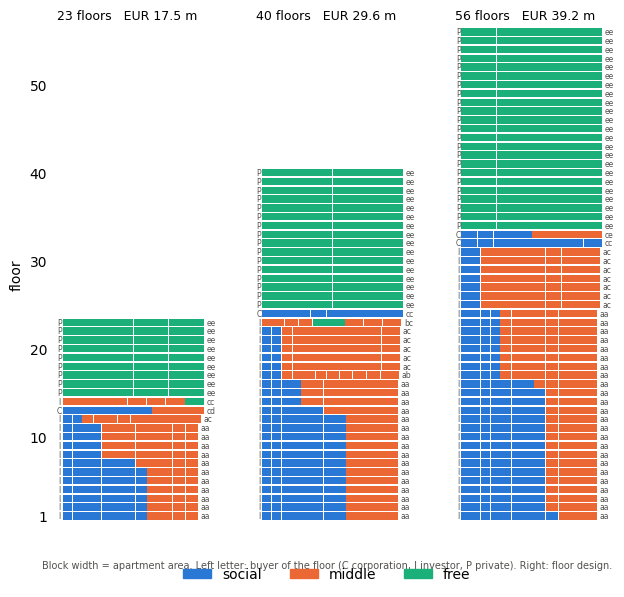

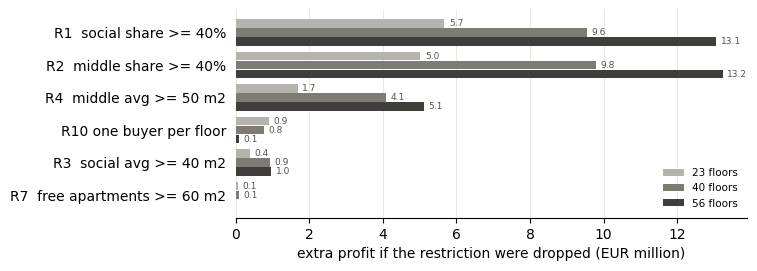

In [14]:
SECTOR_COL = {"social": "#2a78d6", "middle": "#eb6834", "free": "#1baf7a"}
INK2, GRID = "#52514e", "#e4e3df"
OWNER_TXT = {"corporation": "C", "investor": "I", "private": "P"}

# Figure 1: the optimal towers
fig, axes = plt.subplots(1, len(towers), figsize=(7.2, 6.4), sharey=True, gridspec_kw={"wspace": 0.25})
width = max(sum(a[0] for a in f["apts"]) for fl in towers.values() for f in fl)
for ax, (N, floors) in zip(axes, towers.items()):
    for i, f in enumerate(floors):
        xpos = 0
        for s, k in f["apts"]:
            ax.add_patch(Rectangle((xpos, i + 0.08), s - 1.5, 0.84, color=SECTOR_COL[k], lw=0))
            xpos += s
        ax.text(-12, i + 0.5, OWNER_TXT[f["owner"]], ha="center", va="center", fontsize=5.5, color=INK2)
        ax.text(xpos + 8, i + 0.5, f["design"], ha="left", va="center", fontsize=5.5, color=INK2)
    ax.set_xlim(-22, width + 45); ax.set_ylim(0, max(towers))
    ax.set_title(f"{N} floors   EUR {objective[N]/1e6:.1f} m", fontsize=9, loc="left")
    ax.set_xticks([]); ax.tick_params(left=False)
    for sp in ax.spines.values():
        sp.set_visible(False)
axes[0].set_yticks([0.5, 9.5, 19.5, 29.5, 39.5, 49.5]); axes[0].set_yticklabels(["1", "10", "20", "30", "40", "50"])
axes[0].set_ylabel("floor")
fig.legend(handles=[Patch(color=c, label=k) for k, c in SECTOR_COL.items()],
           loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.005))
fig.text(0.5, 0.035, "Block width = apartment area. Left letter: buyer of the floor "
         "(C corporation, I investor, P private). Right: floor design.", ha="center", fontsize=7, color=INK2)
fig.savefig("fig_towers.pdf", bbox_inches="tight")
plt.show()

# Figure 2: cost of each restriction (needs section 9)
if gains:
    labels = {"R1": "R1  social share >= 40%", "R2": "R2  middle share >= 40%",
              "R4": "R4  middle avg >= 50 m2", "R10": "R10 one buyer per floor",
              "R3": "R3  social avg >= 40 m2", "R7": "R7  free apartments >= 60 m2"}
    cols = ["#b5b3ab", "#7d7b74", "#3f3e3a"]
    fig, ax = plt.subplots(figsize=(6.6, 2.7))
    h = 0.26
    for j, N in enumerate(gains):
        vals = [gains[N][r] / 1e6 for r in labels]
        ys = [i + (j - 1) * (h + 0.02) for i in range(len(labels))]
        ax.barh(ys, vals, height=h, color=cols[j], label=f"{N} floors", lw=0)
        for yv, v in zip(ys, vals):
            if v > 0:
                ax.text(v + 0.12, yv, f"{v:.1f}", va="center", fontsize=6.5, color=INK2)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels.values()); ax.invert_yaxis()
    ax.set_xlabel("extra profit if the restriction were dropped (EUR million)")
    ax.xaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
    for sp in ["top", "right", "left"]:
        ax.spines[sp].set_visible(False)
    ax.tick_params(left=False); ax.legend(frameon=False, loc="lower right", fontsize=7.5)
    fig.savefig("fig_sensitivity.pdf", bbox_inches="tight")
    plt.show()
else:
    print("Figure 2 skipped (needs RUN_SENSITIVITY = True).")

## 12. Cross-check with a floor-by-floor model (optional, slow)
A straightforward model with variables for every floor and R12 as explicit ordering constraints.
Its optimum must equal the compact model's. Only runs when `RUN_CROSSCHECK = True`.

Result reported in the report (23 floors, 30 minutes per solver): CBC and HiGHS both reached
exactly EUR 17,483,910.86, the compact optimum, and no better design, without proving optimality.

In [15]:
def floor_model(N, time_limit, solver_name="cbc"):
    p = profit[N]
    F = range(N)
    M = max(max(c.values()) for c in n.values())
    mind = {d: min(n[d]) for d in DESIGNS}
    m = pulp.LpProblem(f"floor_{N}", pulp.LpMaximize)
    z = {(f, d): pulp.LpVariable(f"z_{f}_{d}", cat="Binary") for f in F for d in DESIGNS}    # design of floor f
    w = {(f, o): pulp.LpVariable(f"w_{f}_{o}", cat="Binary") for f in F for o in OWNERS}     # buyer of floor f
    hs = {f: pulp.LpVariable(f"hs_{f}", cat="Binary") for f in F}                             # floor has social
    hf = {f: pulp.LpVariable(f"hf_{f}", cat="Binary") for f in F}                             # floor has free
    v = {(f, s, o, k): pulp.LpVariable(f"v_{f}_{s}_{o}_{k}", lowBound=0, cat="Integer")
         for f in F for s in AREAS for o in OWNERS for k in SECTORS if allowed(s, k, o)}       # R5-R8

    m += pulp.lpSum(p[s, k, o] * var for (f, s, o, k), var in v.items())
    for f in F:
        m += pulp.lpSum(z[f, d] for d in DESIGNS) == 1
        m += pulp.lpSum(w[f, o] for o in OWNERS) == 1
        m += hs[f] + hf[f] <= 1                                                               # R11
        for s in AREAS:
            m += (pulp.lpSum(var for (ff, ss, o, k), var in v.items() if ff == f and ss == s)
                  == pulp.lpSum(n[d].get(s, 0) * z[f, d] for d in DESIGNS))
    for (f, s, o, k), var in v.items():
        m += var <= M * w[f, o]                                                               # R10
        if k == "social": m += var <= M * hs[f]
        if k == "free":   m += var <= M * hf[f]
    for f in range(N - 1):                                                                    # R12
        m += pulp.lpSum(mind[d] * z[f, d] for d in DESIGNS) <= pulp.lpSum(mind[d] * z[f + 1, d] for d in DESIGNS)
    tot = pulp.lpSum(n_tot[d] * z[f, d] for f in F for d in DESIGNS)
    cnt = lambda k: pulp.lpSum(var for (f, s, o, kk), var in v.items() if kk == k)
    ar = lambda k: pulp.lpSum(s * var for (f, s, o, kk), var in v.items() if kk == k)
    for k in ALPHA:
        m += cnt(k) >= ALPHA[k] * tot                                                         # R1, R2
        m += ar(k) >= A_MIN[k] * cnt(k)                                                       # R3, R4
    m += pulp.lpSum(var for (f, s, o, k), var in v.items() if o == "investor") >= BETA * tot  # R9

    solver = (pulp.HiGHS(msg=False, timeLimit=time_limit) if solver_name == "highs"
              else pulp.PULP_CBC_CMD(msg=False, timeLimit=time_limit))
    m.solve(solver)
    return pulp.value(m.objective), m.sol_status == 1, len(m.variables())

if RUN_CROSSCHECK:
    for N in CROSSCHECK_CASES:
        val, proven, nvar = floor_model(N, CROSSCHECK_TIME_LIMIT, CROSSCHECK_SOLVER)
        print(f"{N} floors: compact EUR {objective[N]:,.2f} | floor model ({nvar} variables, "
              f"{CROSSCHECK_SOLVER}) EUR {val:,.2f} | proven optimal: {proven} | "
              f"difference {val - objective[N]:,.2f}")
else:
    print("Skipped (set RUN_CROSSCHECK = True to run; takes up to "
          f"{CROSSCHECK_TIME_LIMIT // 60} minutes per case).")

Skipped (set RUN_CROSSCHECK = True to run; takes up to 30 minutes per case).
